# ABJK (2022) 隔夜涨／日内反转：美股、A 股与香港市场

**赛道：Extend。** 美股与 A 股是最小可辩护基准，香港是核心样本外扩展；这避免把作业拆成多个浅层项目。

**一句话结论（2014-01 至 2026-08 回报窗口）：** 香港的 AB_NR 高减低组合呈现强烈的“隔夜正、日内负”分解，但总收益只边际显著，且在合理成本和 placebo 后不足以支持可交易 alpha；近期美股与 A 股的总收益预测均不显著。

数据更新日：**2026-09-22**。为避免把未完结的 2026-09 当成完整月，回测只使用完整月；原始审计仍保留最新日线。

## 1. 论文、动机与精确构造

[Akbas, Boehmer, Jiang & Koch (2022)](https://doi.org/10.1016/j.jfineco.2021.09.019) 的机制是：隔夜时段较多由噪声／散户需求主导，日内套利者反向纠正；当“隔夜涨、日内跌”异常频繁时，日内可能过度纠正，形成低估并预测后续收益。

对股票 $i$、交易日 $d$：

$$r^{ON}_{i,d}=Open_{i,d}/Close_{i,d-1}-1,\qquad r^{DAY}_{i,d}=Close_{i,d}/Open_{i,d}-1$$

若 $r^{ON}>0$ 且 $r^{DAY}<0$，记为一次 negative daytime reversal。月度频率为

$$NR_{i,t}=\#\{r^{ON}>0,r^{DAY}<0\}/\#\{\text{有效交易日}\},\qquad
AB\_NR_{i,t}=NR_{i,t}/\overline{NR}_{i,t-12:t-1}.$$

严格跟随原文：每月至少 15 个有效交易日；过去 12 个月至少 10 个非缺失月。月末按 AB_NR 分组，持有下月。原文用 CRSP 1993–2017、十分组；此处因港股截面较小，三个市场统一用**等权五分组**。

**为什么选它：** 该信号不只给出收益预测，还给出可证伪的时段分解与顺序 placebo；香港的活跃散户、午间不连续交易及 T+0 架构使其成为有经济含义、而非仅“换一个国家”的扩展。

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from scripts.abjk2022_replication import (
    snapshot_universe, download_market_data, data_quality_report, write_manifest,
    construct_daily, construct_monthly, eligible_monthly, assign_groups,
    portfolio_returns, group_return_summary, spread_summary, nw_mean_stats, fama_macbeth,
    strategy_turnover, cost_scenarios, manual_checks,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

AS_OF = "2026-09-22"
START = "2014-01-01"
END_EXCLUSIVE = "2026-09-23"
LAST_COMPLETE_MONTH = "2026-08"
REFRESH_DATA = False  # 改为 True 才会重新抓取；默认使用本次冻结快照
DATA = ROOT / "data" / "abjk2022"
RESULTS = DATA / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

## 2. 免费数据、样本冻结与检查

- 美股：当前 S&P 500；A 股：当前 CSI 300；港股：当前恒生指数。
- 与原文一致剔除金融和公用事业；月末价格须大于 1 个本币单位。
- Yahoo Finance `auto_adjust=True`，OHLC 同步按拆股／分红调整；无付费数据。
- 这是**当前成分股快照**，存在存活者偏差；不能等同于 CRSP/Compustat 的历史成分、退市收益与市值权重。

In [2]:
universe_path = DATA / f"universe_{AS_OF}.csv"
universe = snapshot_universe(universe_path, refresh=REFRESH_DATA)
raw = download_market_data(
    universe, DATA, start=START, end=END_EXCLUSIVE,
    refresh=REFRESH_DATA, batch_size=50,
)
manifest = write_manifest(
    DATA / "manifest.json", raw, universe_path,
    {"download_date": AS_OF, "start": START, "end_exclusive": END_EXCLUSIVE,
     "last_complete_month": LAST_COMPLETE_MONTH},
)

quality = data_quality_report(raw, universe)
display(universe.groupby(["market", "index"]).size().rename("requested_after_sector_filter").to_frame())
display(quality.style.format({"coverage": "{:.2%}", "open_missing_pct": "{:.3f}",
                              "close_missing_pct": "{:.3f}", "zero_volume_pct": "{:.3f}"}))
print("最新交易日：", manifest["latest_dates"], "；总行数：", f"{manifest['rows']:,}")

,,requested_after_sector_filter
market,index,
CN,CSI 300,238
HK,Hang Seng,69
US,S&P 500,396


,market,requested,received,coverage,rows,first_date,latest_date,open_missing_pct,close_missing_pct,zero_volume_pct,duplicate_keys
0,CN,238,237,99.58%,645591,2014-01-02 00:00:00,2026-09-22 00:00:00,0.000,0.000,2.240,0
1,HK,69,69,100.00%,180027,2014-01-02 00:00:00,2026-09-22 00:00:00,0.000,0.000,0.722,0
2,US,396,396,100.00%,1206941,2014-01-02 00:00:00,2026-09-21 00:00:00,0.000,0.000,0.327,0


最新交易日： {'CN': '2026-09-22', 'HK': '2026-09-22', 'US': '2026-09-21'} ；总行数： 2,032,559


审计规则：不对缺失股票做前向填充；零成交量日保留在原始审计中，但只有可计算 close-to-close 收益的行才进入月度构造。唯一完全缺失的成分股是已终止上市的 `601989.SS`，因此 A 股覆盖率为 237/238。

## 3. 五只股票逐项核验

下表直接展示最近一日的复权前收、开、收盘及两段收益。最后一列检查
$(1+r^{ON})(1+r^{DAY})-1=r^{CC}$；`NR_flag=True` 必须同时满足隔夜为正、日内为负。

In [3]:
daily = construct_daily(raw)
check_tickers = ["AAPL", "MSFT", "600519.SS", "000333.SZ", "0700.HK"]
checks = manual_checks(daily, check_tickers)
assert len(checks) == 5
assert checks["identity_error"].abs().max() < 1e-12
assert checks["NR_flag"].eq(
    checks["overnight=open/prev_close-1"].gt(0) & checks["daytime=close/open-1"].lt(0)
).all()

check_view = checks.copy()
for c in ["overnight=open/prev_close-1", "daytime=close/open-1", "close_to_close", "recombined"]:
    check_view[c] *= 100
display(check_view.style.format({
    "prev_adj_close": "{:.4f}", "adj_open": "{:.4f}", "adj_close": "{:.4f}",
    "overnight=open/prev_close-1": "{:.4f}%", "daytime=close/open-1": "{:.4f}%",
    "close_to_close": "{:.4f}%", "recombined": "{:.4f}%", "identity_error": "{:.2e}",
}))
checks.to_csv(RESULTS / "manual_check_5_stocks.csv", index=False, encoding="utf-8-sig")
print("全样本收益恒等式最大绝对误差：", f"{daily['identity_error'].abs().max():.2e}")

,market,ticker,date,prev_adj_close,adj_open,adj_close,overnight=open/prev_close-1,daytime=close/open-1,close_to_close,recombined,identity_error,NR_flag
0,US,AAPL,2026-09-21 00:00:00,336.1300,335.2800,338.9800,-0.2529%,1.1036%,0.8479%,0.8479%,0.00e+00,False
1,US,MSFT,2026-09-21 00:00:00,493.7800,494.9500,501.6100,0.2370%,1.3456%,1.5857%,1.5857%,0.00e+00,False
2,CN,600519.SS,2026-09-22 00:00:00,1252.5699,1252.1500,1253.8000,-0.0335%,0.1318%,0.0982%,0.0982%,0.00e+00,False
3,CN,000333.SZ,2026-09-22 00:00:00,80.9000,84.9000,82.5400,4.9444%,-2.7797%,2.0272%,2.0272%,0.00e+00,True
4,HK,0700.HK,2026-09-22 00:00:00,430.0000,442.8000,451.6000,2.9767%,1.9874%,5.0233%,5.0233%,-2.22e-16,False


全样本收益恒等式最大绝对误差： 3.55e-15


## 4. 信号、分组与下月收益

排序采用月内 `rank(method='first')` 后等量五分组，解决 AB_NR 离散值的并列问题；只有每个市场／月不少于 25 只股票时才分组。收益均为简单收益并按日复合。

In [4]:
monthly_path = DATA / "monthly_features.parquet"
if monthly_path.exists() and not REFRESH_DATA:
    monthly = pd.read_parquet(monthly_path)
else:
    monthly = construct_monthly(daily)
    monthly.to_parquet(monthly_path, index=False)

panel = eligible_monthly(monthly, LAST_COMPLETE_MONTH)
grouped = assign_groups(panel, signal="ab_nr", n_groups=5)
by_group, spreads = portfolio_returns(grouped, n_groups=5)

sample = panel.groupby("market").agg(
    stock_months=("ticker", "size"), stocks=("ticker", "nunique"),
    months=("month", "nunique"), first_signal_month=("month", "min"),
    last_signal_month=("month", "max"), median_ab_nr=("ab_nr", "median"),
)
display(sample)
group_table = group_return_summary(by_group).pivot(index="group", columns="market", values="mean")
display(group_table.style.format("{:.3f}%"))

,stock_months,stocks,months,first_signal_month,last_signal_month,median_ab_nr
market,,,,,,
CN,28788,237,140,2014-11,2026-07,0.9855
HK,7960,69,141,2014-11,2026-07,0.9849
US,52976,393,141,2014-11,2026-07,0.9874


market,CN,HK,US
group,,,
1,1.705%,0.965%,1.429%
2,1.776%,1.281%,1.366%
3,1.681%,1.259%,1.220%
4,1.549%,0.943%,1.507%
5,1.590%,1.455%,1.557%


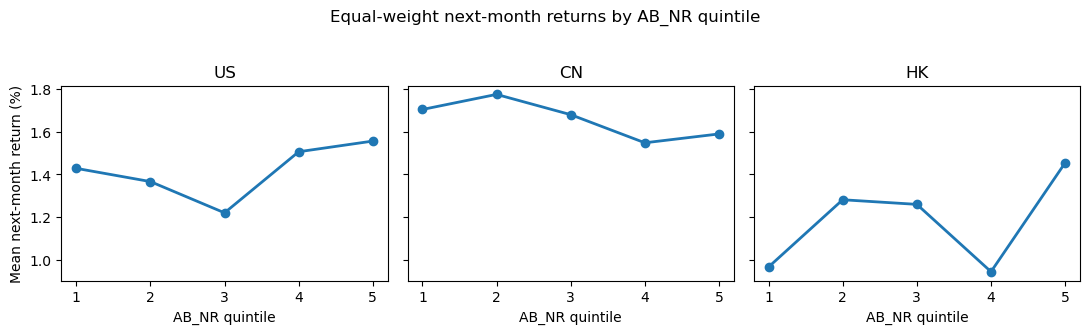

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, market in zip(axes, ["US", "CN", "HK"]):
    s = group_table[market]
    ax.plot(s.index, s.values, marker="o", linewidth=2)
    ax.set(title=market, xlabel="AB_NR quintile", xticks=range(1, 6))
axes[0].set_ylabel("Mean next-month return (%)")
fig.suptitle("Equal-weight next-month returns by AB_NR quintile", y=1.03)
fig.tight_layout()
plt.show()

### 美股与原文的可比性检查

原文主表为全 NYSE/AMEX/NASDAQ 的等权**十分组**，而本研究主表因香港截面小采用五分组。下表仅改变分组数和观察时段，仍使用同一份 2026 年成分股快照，因此不是对原文历史股票池的重建。

In [6]:
us_panel = panel.loc[panel["market"].eq("US")]
us_checks = []
for n_groups in [5, 10]:
    _, s = portfolio_returns(assign_groups(us_panel, n_groups=n_groups), n_groups=n_groups)
    for period, begin, end in [
        ("原文末段重叠", "2014-11", "2017-11"),
        ("2018 年以后", "2017-12", "2026-07"),
        ("全部可用月份", "2014-11", "2026-07"),
    ]:
        segment = s.loc[s["month"].between(pd.Period(begin, "M"), pd.Period(end, "M"))]
        us_checks.append({"groups": n_groups, "period": period, **nw_mean_stats(segment["next_ret"])})
us_sensitivity = pd.DataFrame(us_checks)
display(us_sensitivity[["groups", "period", "months", "mean_pct", "t_hac"]]
        .style.format({"mean_pct": "{:.3f}%", "t_hac": "{:.2f}"}))
us_sensitivity.to_csv(RESULTS / "us_group_period_sensitivity.csv", index=False, encoding="utf-8-sig")

,groups,period,months,mean_pct,t_hac
0,5,原文末段重叠,37,0.141%,0.53
1,5,2018 年以后,104,0.124%,0.45
2,5,全部可用月份,141,0.128%,0.60
3,10,原文末段重叠,37,0.207%,0.95
4,10,2018 年以后,104,0.214%,0.56
5,10,全部可用月份,141,0.212%,0.74


## 5. 统计推断与收益拆解

H-L 为多头 Q5、空头 Q1。t 值来自“月均值对常数回归”的 Newey-West HAC（12 阶滞后），与原文口径一致。隔夜与日内分量分别在下月内复合，因此两者相加只近似总简单收益，交叉乘积解释微小差异。

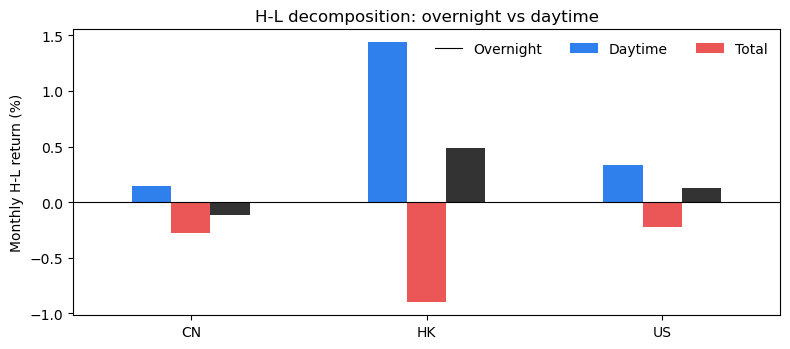

In [7]:
spread_stats = spread_summary(spreads)
display(spread_stats.pivot(index="market", columns="component", values=["mean_pct", "t_hac"])
        .style.format("{:.3f}"))

decomp = spread_stats.pivot(index="market", columns="component", values="mean_pct")
decomp = decomp[["next_overnight_ret", "next_daytime_ret", "next_ret"]]
ax = decomp.plot(kind="bar", figsize=(8, 3.6), color=["#2F80ED", "#EB5757", "#333333"])
ax.axhline(0, color="black", linewidth=.8)
ax.set(ylabel="Monthly H-L return (%)", xlabel="", title="H-L decomposition: overnight vs daytime")
ax.legend(["Overnight", "Daytime", "Total"], frameon=False, ncol=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

截面回归每月将解释变量 1%/99% winsorize 后标准化；报告月度系数均值及 HAC t 值。控制项只使用免费日线可构造的当月收益、6 月动量、波动率、对数成交额和 Amihud 非流动性，不能替代原文完整的 Compustat/机构持仓控制。

In [8]:
predictors = ["ab_nr", "ab_dopr", "ret", "mom_6m", "volatility", "log_adv", "amihud_million"]
fmb, monthly_betas = fama_macbeth(panel, predictors)
display(fmb.pivot(index="predictor", columns="market", values=["coef_pct_per_1sd", "t_hac"])
        .style.format("{:.3f}"))

## 6. Placebo：先日内跌、再隔夜涨

原文的顺序 placebo 是 `DOPR`：日 $d$ 的日内收益为负，随后日 $d+1$ 的隔夜收益为正；`AB_DOPR` 用相同的过去 12 月标准化。月末最后一日因次日开盘在下月，置为非事件，确保月末建仓时不读到未来信息。若 AB_NR 机制独特，placebo 不应稳定预测下月收益。

In [9]:
placebo_grouped = assign_groups(panel, signal="ab_dopr", n_groups=5)
_, placebo_spreads = portfolio_returns(placebo_grouped, n_groups=5)
placebo_stats = spread_summary(placebo_spreads).query("component == 'next_ret'")
compare = (spread_stats.query("component == 'next_ret'")
           [["market", "mean_pct", "t_hac"]]
           .rename(columns={"mean_pct": "AB_NR H-L %", "t_hac": "AB_NR t"})
           .merge(placebo_stats[["market", "mean_pct", "t_hac"]]
                  .rename(columns={"mean_pct": "AB_DOPR H-L %", "t_hac": "AB_DOPR t"}), on="market"))
display(compare.style.format({c: "{:.3f}" for c in compare.columns if c != "market"}))

,market,AB_NR H-L %,AB_NR t,AB_DOPR H-L %,AB_DOPR t
0,CN,-0.115,-0.468,-0.410,-1.462
1,HK,0.490,1.641,-0.651,-2.007
2,US,0.128,0.602,-0.105,-0.495


## 7. 换手率与成本情景

每条腿等权，月度单边换手率为 $0.5\sum|w_t-w_{t-1}|$；表中 `avg_two_leg_turnover` 是多、空两腿之和。成本按给定的**往返基点数 × 两腿单边换手率**从 H-L 毛收益扣除。A 股的空头腿在现实中受融券约束，因此仅应理解为学术价格检验。

In [10]:
turnover = strategy_turnover(grouped, n_groups=5)
cost_table = cost_scenarios(spreads, turnover, costs_bps=(0, 10, 25, 50))
display(cost_table[["market", "roundtrip_cost_bps", "avg_two_leg_turnover",
                    "mean_pct", "t_hac", "ann_sharpe", "months"]]
        .style.format({"avg_two_leg_turnover": "{:.3f}x", "mean_pct": "{:.3f}%",
                       "t_hac": "{:.2f}", "ann_sharpe": "{:.2f}"}))

,market,roundtrip_cost_bps,avg_two_leg_turnover,mean_pct,t_hac,ann_sharpe,months
0,CN,0,1.487x,-0.116%,-0.47,-0.09,139
1,CN,10,1.487x,-0.265%,-1.07,-0.21,139
2,CN,25,1.487x,-0.488%,-1.98,-0.39,139
3,CN,50,1.487x,-0.860%,-3.50,-0.69,139
4,HK,0,1.541x,0.498%,1.64,0.41,140
5,HK,10,1.541x,0.343%,1.13,0.28,140
6,HK,25,1.541x,0.112%,0.37,0.09,140
7,HK,50,1.541x,-0.273%,-0.90,-0.22,140
8,US,0,1.576x,0.126%,0.59,0.17,140
9,US,10,1.576x,-0.032%,-0.15,-0.04,140


## 8. 结论：三个市场放在一起

In [11]:
main = spread_stats.query("component == 'next_ret'").set_index("market")
night = spread_stats.query("component == 'next_overnight_ret'").set_index("market")
day = spread_stats.query("component == 'next_daytime_ret'").set_index("market")
net25 = cost_table.query("roundtrip_cost_bps == 25").set_index("market")
fmb_abnr = fmb.query("predictor == 'ab_nr'").set_index("market")

summary = pd.DataFrame({
    "gross_HL_pct": main["mean_pct"], "gross_t": main["t_hac"],
    "overnight_HL_pct": night["mean_pct"], "daytime_HL_pct": day["mean_pct"],
    "FMB_ABNR_pct_per_1sd": fmb_abnr["coef_pct_per_1sd"], "FMB_t": fmb_abnr["t_hac"],
    "net_25bps_pct": net25["mean_pct"], "net_25bps_t": net25["t_hac"],
}).reindex(["US", "CN", "HK"])
display(summary.style.format("{:.3f}"))

display(Markdown(f'''
- **美股：未复现原文的近期总收益强度。** H-L 为 **{main.loc['US','mean_pct']:.2f}%/月**（t={main.loc['US','t_hac']:.2f}）；隔夜为正、日内为负，方向吻合，但净效应弱。原文 1993–2017 等权十分组为 0.92%/月，本结果不可与之视为同样本复算。
- **A 股：总收益为零附近。** H-L 为 **{main.loc['CN','mean_pct']:.2f}%/月**（t={main.loc['CN','t_hac']:.2f}），与既有中国样本外研究的“缺乏总收益预测”方向一致。
- **香港：时段机制最强，但交易结论较弱。** 毛 H-L 为 **{main.loc['HK','mean_pct']:.2f}%/月**（t={main.loc['HK','t_hac']:.2f}）；隔夜 **{night.loc['HK','mean_pct']:.2f}%**、日内 **{day.loc['HK','mean_pct']:.2f}%**。25 bps 往返成本后仅 **{net25.loc['HK','mean_pct']:.2f}%/月**（t={net25.loc['HK','t_hac']:.2f}）。
- **最保守判断：** 香港结果支持“隔夜压力—日内反转”的描述性图样；修正月末前视后，placebo H-L 为 **{placebo_stats.set_index('market').loc['HK','mean_pct']:.2f}%/月**（t={placebo_stats.set_index('market').loc['HK','t_hac']:.2f}），也有显著的反向预测。联合回归中 AB_NR 为正（t={fmb_abnr.loc['HK','t_hac']:.2f}），但这还不足以证明原文所述的唯一机制。总收益只边际显著且成本敏感，因此它更像机制研究候选，而不是部署就绪的 alpha。
'''))

,gross_HL_pct,gross_t,overnight_HL_pct,daytime_HL_pct,FMB_ABNR_pct_per_1sd,FMB_t,net_25bps_pct,net_25bps_t
market,,,,,,,,
US,0.128,0.602,0.336,-0.219,0.100,1.369,-0.268,-1.250
CN,-0.115,-0.468,0.143,-0.281,0.029,0.333,-0.488,-1.979
HK,0.490,1.641,1.436,-0.899,0.369,2.186,0.112,0.371



- **美股：未复现原文的近期总收益强度。** H-L 为 **0.13%/月**（t=0.60）；隔夜为正、日内为负，方向吻合，但净效应弱。原文 1993–2017 等权十分组为 0.92%/月，本结果不可与之视为同样本复算。
- **A 股：总收益为零附近。** H-L 为 **-0.11%/月**（t=-0.47），与既有中国样本外研究的“缺乏总收益预测”方向一致。
- **香港：时段机制最强，但交易结论较弱。** 毛 H-L 为 **0.49%/月**（t=1.64）；隔夜 **1.44%**、日内 **-0.90%**。25 bps 往返成本后仅 **0.11%/月**（t=0.37）。
- **最保守判断：** 香港结果支持“隔夜压力—日内反转”的描述性图样；修正月末前视后，placebo H-L 为 **-0.65%/月**（t=-2.01），也有显著的反向预测。联合回归中 AB_NR 为正（t=2.19），但这还不足以证明原文所述的唯一机制。总收益只边际显著且成本敏感，因此它更像机制研究候选，而不是部署就绪的 alpha。


## 9. 能辩护的边界

1. **存活者偏差：** 使用 2026-09-22 当前成分股，缺少历史调入调出与退市收益；不能宣称严格复制 CRSP。
2. **免费数据误差：** Yahoo 的复权与 CRSP 总收益定义可能不同；开盘集合竞价、午休和价格限制也跨市场异质。
3. **等权且无历史市值：** 这是最接近论文显著结果的主规格，也最偏向小盘股；原文市值加权 H-L 本来就不显著。
4. **成本不是完整冲击模型：** 未建模借券费、A 股卖空限制、印花税差异、盘口冲击与容量；成本结果应视为乐观上界。
5. **推断：** 三市场比较与多种规格带来多重检验；香港 t=1.64 不能作为常规 5% 显著证据。

### 参考

- Akbas, F., Boehmer, E., Jiang, C., & Koch, P. D. (2022), *Journal of Financial Economics*, 145(3), 850–875. [DOI](https://doi.org/10.1016/j.jfineco.2021.09.019)
- Cheema, M. A., Chiah, M., & Man, Y. (2022), “Is China different?”, *Pacific-Basin Finance Journal*, 74, 101809. [DOI](https://doi.org/10.1016/j.pacfin.2022.101809)
- 成分股快照：[S&P 500](https://en.wikipedia.org/wiki/List_of_S%26P_500_companies)、[CSI 300](https://en.wikipedia.org/wiki/CSI_300_Index)、[Hang Seng Index](https://en.wikipedia.org/wiki/Hang_Seng_Index)；价格源：Yahoo Finance（通过 yfinance）。

In [12]:
# 保存所有核心结果，便于逐表核对或做 slide。
outputs = {
    "group_returns": by_group, "spreads": spreads, "spread_summary": spread_stats,
    "placebo_spreads": placebo_spreads, "fama_macbeth": fmb,
    "turnover": turnover, "cost_scenarios": cost_table,
}
for name, frame in outputs.items():
    frame.to_csv(RESULTS / f"{name}.csv", index=False, encoding="utf-8-sig")
print("结果目录：", RESULTS.resolve())

结果目录： E:\Jupyter notebook\EntroPy\data\abjk2022\results
